# AI Training Model — Architecture → Quantization → ESP32-S3

**Benchmark tổng hợp trên Front-End C4** · Phục vụ khảo sát và biện luận lựa chọn mô hình TinyML cho NCKH.

> **Phạm vi:** Bảy biến thể kiến trúc (V1, V2, V3, V4.0, V4.1, V5, V6), mỗi biến thể có Test FP32 và báo cáo các phương pháp lượng tử hóa; hai ứng viên V1/QAT và V3/PTQ có log `Phase4_Deployment_Artifacts/Log_Deploy/`.
>
> **Quyết định của nguyên mẫu:** chọn **V1 / C4 / s44 / QAT INT8** (artifact đã static profiling), không tuyên bố tối ưu toàn cục. Đây là **phân loại âm thanh nghiên cứu**, không phải công cụ chẩn đoán độc lập.

### Nguyên tắc đọc
- Cùng C4: `pre_emphasis=0`, `n_mels=40`, `n_fft=2048`, `hop_length=625`, tensor `40×129×1`.
- **Accuracy** trong các báo cáo là kết quả **historical Test 159 WAV**, đã được tham khảo nhiều vòng nghiên cứu; **không coi là Test độc lập hoàn toàn**.
- **Model size ≠ toàn bộ Flash chương trình; TensorArena used ≠ tổng RAM firmware**.
- Có **hai artifact V1 QAT** cần giữ riêng: bản ở `Quantization_Report` mới (93,08%) và bản trong D/đã profiling (95,60%). Chưa xác minh chúng có cùng file hash hoặc QAT recipe.

## 0. Sử dụng notebook ở root

Đặt `AI_Training_Model_Benchmark_Final.ipynb` tại **`AI_Training_Model/`** (ngang hàng thư mục `Phase3_Quantization_Model/` và `Phase4_Deployment_Artifacts/`).

Notebook có **snapshot đóng gói** đúng theo các báo cáo đã gửi nên vẫn chạy khi không có các báo cáo trong máy. Nếu dự án lưu các file `Test_Report.txt`, `Quantization_Report.txt` và log ở các thư mục con, mục 1 sẽ **tự tìm và đối chiếu** những file đó; không tự sửa số liệu snapshot khi nguồn không khớp. Không cần đặt file ngoài notebook để xem kết quả hiện có.

Tối ưu cho Python 3 với `pandas`, `numpy`, `matplotlib`, `IPython`. Chạy **Run All**.

In [29]:
from pathlib import Path
import re, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def find_ai_training_root(start: Path) -> Path:
    """Tìm AI_Training_Model dù kernel mở tại repo root hay thư mục notebook."""
    start = start.resolve()
    for base in (start, *start.parents):
        for candidate in (base, base / 'AI_Training_Model'):
            if ((candidate / 'Phase2_Preprocess_&_Traning').is_dir() and
                (candidate / 'Phase3_Quantization_Model').is_dir() and
                (candidate / 'Phase4_Deployment_Artifacts').is_dir()):
                return candidate.resolve()
    raise FileNotFoundError('Không tìm thấy root AI_Training_Model từ ' + str(start))

ROOT = find_ai_training_root(Path.cwd())
PHASE2_DIR = ROOT / 'Phase2_Preprocess_&_Traning'
PHASE3_DIR = ROOT / 'Phase3_Quantization_Model'
PHASE4_DIR = ROOT / 'Phase4_Deployment_Artifacts'
LOG_DEPLOY_DIR = PHASE4_DIR / 'Log_Deploy'
MODELS = ['V1', 'V2', 'V3', 'V4.0', 'V4.1', 'V5', 'V6']
MODEL_NAMES = {'V1':'Separable CNN + Flatten', 'V2':'DS-CNN + GAP', 'V3':'HelloEdge', 'V4.0':'MobileNet V4.0', 'V4.1':'MobileNet V4.1', 'V5':'ERespiNet', 'V6':'Separable CNN + GAP'}
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format',lambda x: f'{x:,.2f}')
print('AI_Training_Model root:', ROOT)

AI_Training_Model root: D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model


## 1. Nguồn dữ liệu, khả năng tái lập và kiểm tra artifact

Các snapshot sau **được trích từ báo cáo người thực hiện cung cấp**, không phải số liệu ước đoán. Các trường `FN/FP` lấy từ confusion matrix (Asthma là nhãn 0). Báo cáo lượng tử **V4.0** không chứa dòng `Output_Quantize_...`, nên được ánh xạ theo file/bộ báo cáo V4.0 đã cung cấp; khi chạy trong dự án, có thể xác minh qua tên thư mục cha.

Mọi chỉ số profiling bên dưới đều là **static Invoke**, chưa có thời gian xử lý Microphone / DSP.

In [30]:
# 1.1. Nguồn sự thật: đọc trực tiếp report/log hiện hành, không dùng JSON ghi cứng
def extract_cm(text):
    match = re.search(r'\[\[\s*(\d+)\s+(\d+)\s*\]\s*\[\s*(\d+)\s+(\d+)\s*\]\]', text)
    return tuple(map(int, match.groups())) if match else None

def extract_macro_f1(text):
    match = re.search(r'(?m)^\s*macro avg\s+[\d.]+\s+[\d.]+\s+([\d.]+)\s+\d+', text)
    return round(float(match.group(1)) * 100, 2) if match else None

def read_test_report(text):
    accuracy = re.search(r'(?m)^Test Accuracy:\s*([\d.]+)', text)
    cm = extract_cm(text)
    if not accuracy or not cm:
        return None
    tp, fn, fp, tn = cm
    sha = re.search(r'Config SHA256:\s*([a-f0-9]{64})', text)
    return {'acc': round(float(accuracy.group(1)) * 100, 4), 'fn': fn, 'fp': fp,
            'recall': round(tp / (tp + fn) * 100, 4), 'macro': extract_macro_f1(text),
            'count': sum(cm), 'correct': tp + tn, 'config_sha': sha.group(1) if sha else None}

def read_quant_report(text):
    methods = ('Keras_FP32','TFLite_FP32','PTQ_INT8','QAT_INT8','PTQ_INT16x8')
    sizes = {key: int(value) for key, value in re.findall(
        r'(?m)^(Keras_FP32|TFLite_FP32|PTQ_INT8|QAT_INT8|PTQ_INT16x8):\s*(\d+) bytes', text)}
    hits = list(re.finditer(r'(?m)^\s*(Keras_FP32|TFLite_FP32|PTQ_INT8|QAT_INT8|PTQ_INT16x8)\s*$', text))
    result = {}
    for index, hit in enumerate(hits):
        part = text[hit.end():hits[index + 1].start() if index + 1 < len(hits) else len(text)]
        accuracy = re.search(r'(?m)^Accuracy:\s*([\d.]+)', part)
        cm = extract_cm(part)
        if not accuracy or not cm:
            continue
        tp, fn, fp, tn = cm
        result[hit.group(1)] = {'acc': round(float(accuracy.group(1)) * 100, 4),
            'fn': fn, 'fp': fp, 'recall': round(tp / (tp + fn) * 100, 4),
            'macro': extract_macro_f1(part), 'correct': tp + tn, 'count': sum(cm),
            'size_b': sizes.get(hit.group(1))}
    return result if set(result) == set(methods) else None

def read_board_log(text):
    def number(pattern):
        match = re.search(pattern, text)
        return float(match.group(1)) if match else None
    def fraction(pattern):
        match = re.search(pattern, text)
        return f'{match.group(1)}/{match.group(2)}' if match else None
    values = {'model_size_b': number(r'Model Flash size\s*:\s*(\d+)'),
        'arena_used_b': number(r'Tensor Arena used\s*:\s*(\d+)'),
        'arena_capacity_b': number(r'Tensor Arena capacity\s*:\s*(\d+)'),
        'latency_ms': number(r'Inference latency avg\s*:\s*[\d.]+ us \(([\d.]+) ms\)'),
        'count': fraction(r'Inference count\s*:\s*(\d+) OK / (\d+) failed'),
        'exact': fraction(r'Python/ESP32 INT8 exact\s*:\s*(\d+)/(\d+)'),
        'label': fraction(r'Python/ESP32 label match\s*:\s*(\d+)/(\d+)'),
        'static': fraction(r'Static sample accuracy\s*:\s*(\d+)/(\d+)'),
        'compatibility': 'PASS' if 'Operator compatibility   : PASS' in text else 'UNKNOWN'}
    return values if values['model_size_b'] is not None and values['latency_ms'] is not None else None

found = {'train': {}, 'quant': {}, 'board': {}}
for path in PHASE2_DIR.glob('Output_Train_*/Test_Report.txt'):
    match = re.search(r'Output_Train_(V[1-6](?:[_\.]?[01])?)', path.parent.name)
    if match:
        model = match.group(1).replace('V4_0','V4.0').replace('V4_1','V4.1')
        if model in MODELS:
            found['train'][model] = str(path.relative_to(ROOT))
for path in PHASE3_DIR.glob('Output_Quantize_*/Quantization_Report.txt'):
    match = re.search(r'Output_Quantize_(V[1-6](?:[_\.]?[01])?)', path.parent.name)
    if match:
        model = match.group(1).replace('V4_0','V4.0').replace('V4_1','V4.1')
        if model in MODELS:
            found['quant'][model] = str(path.relative_to(ROOT))
for candidate, name in [('V1/QAT (artifact đã profiling)','V1_C4_QAT.log'),('V3/PTQ','V3_C4_PTQ.log')]:
    path = LOG_DEPLOY_DIR / name
    if path.is_file():
        found['board'][candidate] = str(path.relative_to(ROOT))

SOURCE_TRAIN, SOURCE_QUANT, SOURCE_BOARD = {}, {}, {}

for model, relative_path in found['train'].items():
    report_path = ROOT / relative_path
    report = read_test_report(report_path.read_text(encoding='utf-8', errors='replace'))
    if report is not None:
        metadata_path = report_path.with_name('Training_Metadata.json')
        if not metadata_path.is_file():
            raise FileNotFoundError(f'Thiếu Training_Metadata.json cho {model}: {metadata_path}')
        metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
        parameter_count = metadata.get('parameter_count')
        if parameter_count is None:
            raise ValueError(f'Training_Metadata.json của {model} thiếu parameter_count')
        SOURCE_TRAIN[model] = {**report, 'parameter_count': int(parameter_count),
                               'source_file': relative_path,
                               'metadata_file': str(metadata_path.relative_to(ROOT))}

for model, relative_path in found['quant'].items():
    report = read_quant_report((ROOT / relative_path).read_text(encoding='utf-8', errors='replace'))
    if report is not None:
        SOURCE_QUANT[model] = {
            method: {**metrics, 'source_file': relative_path}
            for method, metrics in report.items()
        }

for candidate, relative_path in found['board'].items():
    report = read_board_log((ROOT / relative_path).read_text(encoding='utf-8', errors='replace'))
    if report is not None:
        SOURCE_BOARD[candidate] = {**report, 'source_file': relative_path}

missing_train = sorted(set(MODELS) - set(SOURCE_TRAIN))
missing_quant = sorted(set(MODELS) - set(SOURCE_QUANT))
if missing_train or missing_quant:
    raise FileNotFoundError(f'Thiếu report: train={missing_train}, quant={missing_quant}')
if len(SOURCE_BOARD) != 2:
    raise FileNotFoundError(f'Thiếu log profiling: tìm được {list(SOURCE_BOARD)}')

# Giữ tên biến cũ để các cell biểu đồ bên dưới không phải sửa lại.
# Nội dung các biến này hiện được tạo hoàn toàn từ file report/log thật.
SNAPSHOT_TRAIN = {model: {key: value for key, value in row.items() if key != 'source_file'} for model, row in SOURCE_TRAIN.items()}
SNAPSHOT_QUANT = {model: {method: {key: value for key, value in metrics.items() if key != 'source_file'} for method, metrics in methods.items()} for model, methods in SOURCE_QUANT.items()}
SNAPSHOT_BOARD = {name: {key: value for key, value in row.items() if key != 'source_file'} for name, row in SOURCE_BOARD.items()}

source_train_df = pd.DataFrame([{
    'Model': model,
    'Accuracy (%)': SOURCE_TRAIN[model]['acc'],
    'Asthma Recall (%)': SOURCE_TRAIN[model]['recall'],
    'Macro F1 (%)': SOURCE_TRAIN[model]['macro'],
    'Parameters': SOURCE_TRAIN[model]['parameter_count'],
    'FN': SOURCE_TRAIN[model]['fn'],
    'FP': SOURCE_TRAIN[model]['fp'],
    'Đúng/Tổng': f"{SOURCE_TRAIN[model]['correct']}/{SOURCE_TRAIN[model]['count']}",
    'Config SHA256': SOURCE_TRAIN[model]['config_sha'],
    'Nguồn': SOURCE_TRAIN[model]['source_file'],
} for model in MODELS])

source_quant_df = pd.DataFrame([{
    'Model': model,
    'Method': method,
    'Accuracy (%)': SOURCE_QUANT[model][method]['acc'],
    'Asthma Recall (%)': SOURCE_QUANT[model][method]['recall'],
    'Macro F1 (%)': SOURCE_QUANT[model][method]['macro'],
    'FN': SOURCE_QUANT[model][method]['fn'],
    'FP': SOURCE_QUANT[model][method]['fp'],
    'Đúng/Tổng': f"{SOURCE_QUANT[model][method]['correct']}/{SOURCE_QUANT[model][method]['count']}",
    'Model size (B)': SOURCE_QUANT[model][method]['size_b'],
    'Nguồn': SOURCE_QUANT[model][method]['source_file'],
} for model in MODELS for method in ['Keras_FP32','TFLite_FP32','PTQ_INT8','QAT_INT8','PTQ_INT16x8']])

source_board_df = pd.DataFrame([{
    'Candidate': candidate,
    'Model size (B)': values['model_size_b'],
    'Arena used (B)': values['arena_used_b'],
    'Latency avg (ms)': values['latency_ms'],
    'Invoke OK/Fail': values['count'],
    'INT8 exact': values['exact'],
    'Label match': values['label'],
    'Nguồn': values['source_file'],
} for candidate, values in SOURCE_BOARD.items()])

display(Markdown('### Số liệu FP32 đọc trực tiếp từ `Test_Report.txt`'))
display(source_train_df.round(4))
display(Markdown('### Số liệu lượng tử đọc trực tiếp từ `Quantization_Report.txt`'))
display(source_quant_df.round(4))
display(Markdown('### Số liệu ESP32-S3 đọc trực tiếp từ log profiling'))
display(source_board_df.round(4))

### Số liệu FP32 đọc trực tiếp từ `Test_Report.txt`

,Model,Accuracy (%),Asthma Recall (%),Macro F1 (%),Parameters,FN,FP,Đúng/Tổng,Config SHA256,Nguồn
0,V1,90.57,78.95,86.91,331386,8,7,144/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V1_Se...
1,V2,91.82,84.21,88.86,7802,6,7,146/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V2_Se...
2,V3,93.08,92.11,90.89,23617,3,8,148/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V3_He...
3,V4.0,87.42,84.21,83.82,1371361,6,14,139/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V4_0_...
4,V4.1,86.79,84.21,83.14,480321,6,15,138/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V4_1_...
5,V5,92.45,86.84,89.81,351553,5,7,147/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V5_ER...
6,V6,84.28,92.11,81.24,8401,3,22,134/159,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,Phase2_Preprocess_&_Traning\Output_Train_V6_Se...


### Số liệu lượng tử đọc trực tiếp từ `Quantization_Report.txt`

,Model,Method,Accuracy (%),Asthma Recall (%),Macro F1 (%),FN,FP,Đúng/Tổng,Model size (B),Nguồn
0,V1,Keras_FP32,90.57,78.95,86.91,8,7,144/159,4043366,Phase3_Quantization_Model\Output_Quantize_V1\Q...
1,V1,TFLite_FP32,90.57,78.95,86.91,8,7,144/159,1333520,Phase3_Quantization_Model\Output_Quantize_V1\Q...
2,V1,PTQ_INT8,92.45,78.95,89.23,8,4,147/159,347368,Phase3_Quantization_Model\Output_Quantize_V1\Q...
3,V1,QAT_INT8,93.08,89.47,90.74,4,7,148/159,347960,Phase3_Quantization_Model\Output_Quantize_V1\Q...
4,V1,PTQ_INT16x8,90.57,78.95,86.91,8,7,144/159,351136,Phase3_Quantization_Model\Output_Quantize_V1\Q...
5,V2,Keras_FP32,91.82,84.21,88.86,6,7,146/159,160355,Phase3_Quantization_Model\Output_Quantize_V2\Q...
6,V2,TFLite_FP32,91.82,84.21,88.86,6,7,146/159,38548,Phase3_Quantization_Model\Output_Quantize_V2\Q...
7,V2,PTQ_INT8,88.68,84.21,85.21,6,12,141/159,23144,Phase3_Quantization_Model\Output_Quantize_V2\Q...
8,V2,QAT_INT8,92.45,84.21,89.63,6,6,147/159,22944,Phase3_Quantization_Model\Output_Quantize_V2\Q...
9,V2,PTQ_INT16x8,91.82,84.21,88.86,6,7,146/159,26872,Phase3_Quantization_Model\Output_Quantize_V2\Q...


### Số liệu ESP32-S3 đọc trực tiếp từ log profiling

,Candidate,Model size (B),Arena used (B),Latency avg (ms),Invoke OK/Fail,INT8 exact,Label match,Nguồn
0,V1/QAT (artifact đã profiling),"347,968.00","169,380.00","1,164.20",36/0,11/12,12/12,Phase4_Deployment_Artifacts\Log_Deploy\V1_C4_Q...
1,V3/PTQ,"47,448.00","173,188.00","11,452.18",36/0,12/12,12/12,Phase4_Deployment_Artifacts\Log_Deploy\V3_C4_P...


In [31]:
def extract_cm(s):
    m = re.search(r'\[\[\s*(\d+)\s+(\d+)\s*\]\s*\[\s*(\d+)\s+(\d+)\s*\]\]', s)
    return tuple(map(int, m.groups())) if m else None

def extract_macro_f1(s):
    m = re.search(r'(?m)^\s*macro avg\s+[\d.]+\s+[\d.]+\s+([\d.]+)\s+\d+', s)
    return round(float(m.group(1)) * 100, 2) if m else None

def read_test_report(s):
    a = re.search(r'(?m)^Test Accuracy:\s*([\d.]+)', s)
    cm = extract_cm(s)
    if not a or not cm: return None
    tp,fn,fp,tn = cm
    sha=re.search(r'Config SHA256:\s*([a-f0-9]{64})',s)
    return {'acc':round(float(a.group(1))*100,4),'fn':fn,'fp':fp,'recall':round(tp/(tp+fn)*100,4),'macro':extract_macro_f1(s),
            'count':sum(cm),'correct':tp+tn,'config_sha':sha.group(1) if sha else None}

def read_quant_report(s):
    sizes={k:int(v) for k,v in re.findall(r'(?m)^(Keras_FP32|TFLite_FP32|PTQ_INT8|QAT_INT8|PTQ_INT16x8):\s*(\d+) bytes',s)}
    hits=list(re.finditer(r'(?m)^\s*(Keras_FP32|TFLite_FP32|PTQ_INT8|QAT_INT8|PTQ_INT16x8)\s*$',s))
    d={}
    for i,m in enumerate(hits):
        part=s[m.end():hits[i+1].start() if i+1<len(hits) else len(s)]
        acc=re.search(r'(?m)^Accuracy:\s*([\d.]+)',part)
        cm=extract_cm(part)
        if not acc or not cm: continue
        tp,fn,fp,tn=cm
        d[m.group(1)]={'acc':round(float(acc.group(1))*100,4),'fn':fn,'fp':fp,'macro':extract_macro_f1(part),
                       'recall':round(tp/(tp+fn)*100,4),'correct':tp+tn,'count':sum(cm),
                       'size_b':sizes.get(m.group(1))}
    return d if len(d)==5 else None

def read_board_log(s):
    def number(p):
        m=re.search(p,s)
        return float(m.group(1)) if m else None
    def frac(p):
        m=re.search(p,s)
        return f'{m.group(1)}/{m.group(2)}' if m else None
    values=dict(model_size_b=number(r'Model Flash size\s*:\s*(\d+)'),
        arena_used_b=number(r'Tensor Arena used\s*:\s*(\d+)'),
        arena_capacity_b=number(r'Tensor Arena capacity\s*:\s*(\d+)'),
        latency_ms=number(r'Inference latency avg\s*:\s*[\d.]+ us \(([\d.]+) ms\)'),
        count=frac(r'Inference count\s*:\s*(\d+) OK / (\d+) failed'),
        exact=frac(r'Python/ESP32 INT8 exact\s*:\s*(\d+)/(\d+)'),
        label=frac(r'Python/ESP32 label match\s*:\s*(\d+)/(\d+)'),
        static=frac(r'Static sample accuracy\s*:\s*(\d+)/(\d+)'),
        compatibility='PASS' if 'Operator compatibility   : PASS' in s else 'UNKNOWN')
    return values if values['model_size_b'] is not None and values['latency_ms'] is not None else None

# Chỉ đối chiếu output hiện hành; không quét Bacup_Output_Cu hoặc artifact cũ.
found = {'train':{},'quant':{},'board':{}}
for path in PHASE2_DIR.glob('Output_Train_*/Test_Report.txt'):
    m=re.search(r'Output_Train_(V[1-6](?:[_\.]?[01])?)',path.parent.name)
    if not m: continue
    model=m.group(1).replace('V4_0','V4.0').replace('V4_1','V4.1')
    if model not in MODELS: continue
    values=read_test_report(path.read_text(encoding='utf-8',errors='replace'))
    if values: found['train'][model]=str(path.relative_to(ROOT))
for path in PHASE3_DIR.glob('Output_Quantize_*/Quantization_Report.txt'):
    m=re.search(r'Output_Quantize_(V[1-6](?:[_\.]?[01])?)',path.parent.name)
    if not m: continue
    model=m.group(1).replace('V4_0','V4.0').replace('V4_1','V4.1')
    if model in MODELS: found['quant'][model]=str(path.relative_to(ROOT))
for key,name in [('V1/QAT (artifact đã profiling)','V1_C4_QAT.log'),('V3/PTQ','V3_C4_PTQ.log')]:
    for p in [LOG_DEPLOY_DIR/name, ROOT/name]:
        if p.exists():found['board'][key]=str(p.relative_to(ROOT));break
print('Dữ liệu đóng gói: 7 Test + 7 Quant + 2 board logs')
print('Các đường dẫn source tìm thấy trong project:', {k:len(v) for k,v in found.items()})
for kind, items in found.items():
    for model,path in items.items():
        content=(ROOT/path).read_text(encoding='utf-8',errors='replace')
        report={'train':read_test_report,'quant':read_quant_report,'board':read_board_log}[kind](content)
        if report is None:print('⚠ Không parse được', path);continue
        expected={'train':SNAPSHOT_TRAIN,'quant':SNAPSHOT_QUANT,'board':SNAPSHOT_BOARD}[kind][model]
        # Tránh kết luận trùng artifact chỉ dựa trên số đo.
        check_fields={'train':['acc','fn','fp'],'quant':['PTQ_INT8','QAT_INT8'],'board':['model_size_b','latency_ms']}[kind]
        issues=[field for field in check_fields if report.get(field)!=expected.get(field)]
        print(('⚠ KHÁC snapshot' if issues else '✓ Trùng snapshot'),kind,model,path,issues)

Dữ liệu đóng gói: 7 Test + 7 Quant + 2 board logs
Các đường dẫn source tìm thấy trong project: {'train': 7, 'quant': 7, 'board': 2}
✓ Trùng snapshot train V1 Phase2_Preprocess_&_Traning\Output_Train_V1_SepConv2D_Flatten\Test_Report.txt []
✓ Trùng snapshot train V2 Phase2_Preprocess_&_Traning\Output_Train_V2_SeqConv2D_Global\Test_Report.txt []
✓ Trùng snapshot train V3 Phase2_Preprocess_&_Traning\Output_Train_V3_HelloEdge\Test_Report.txt []
✓ Trùng snapshot train V4.0 Phase2_Preprocess_&_Traning\Output_Train_V4_0_MobileNet\Test_Report.txt []
✓ Trùng snapshot train V4.1 Phase2_Preprocess_&_Traning\Output_Train_V4_1_MobileNet\Test_Report.txt []
✓ Trùng snapshot train V5 Phase2_Preprocess_&_Traning\Output_Train_V5_ERespiNet\Test_Report.txt []
✓ Trùng snapshot train V6 Phase2_Preprocess_&_Traning\Output_Train_V6_SepConv2D_GAP\Test_Report.txt []
✓ Trùng snapshot quant V1 Phase3_Quantization_Model\Output_Quantize_V1\Quantization_Report.txt []
✓ Trùng snapshot quant V2 Phase3_Quantization_Mode

## 2. Giai đoạn huấn luyện — FP32 (7 kiến trúc)

Cả bảy `Test_Report` có **cùng SHA256 Front-End C4**, 159 WAV (38 Asthma, 121 Non-Asthma). Xếp hạng này **chỉ mô tả historical Test**; không thay thế bảng Validation nếu sau này muốn chọn lại kiến trúc bằng tiêu chí khách quan hơn.

In [32]:
train_df=pd.DataFrame([{'Model':m,'Kiến trúc':MODEL_NAMES[m],'Acc (%)':SNAPSHOT_TRAIN[m]['acc'],
    'Asthma Recall (%)':SNAPSHOT_TRAIN[m]['recall'],'Macro F1 (%)':SNAPSHOT_TRAIN[m]['macro'],
    'FN':SNAPSHOT_TRAIN[m]['fn'],'FP':SNAPSHOT_TRAIN[m]['fp'],'Đúng/159':SNAPSHOT_TRAIN[m]['correct']} for m in MODELS])
display(train_df.sort_values('Acc (%)',ascending=False).reset_index(drop=True).round({'Acc (%)':2,'Asthma Recall (%)':2,'Macro F1 (%)':2}))
assert len(set(x['config_sha'] for x in SNAPSHOT_TRAIN.values()))==1, 'SHA cấu hình không thống nhất'
assert all(x['count']==159 for x in SNAPSHOT_TRAIN.values())
print('SHA Front-End chung:', SNAPSHOT_TRAIN['V1']['config_sha'])

,Model,Kiến trúc,Acc (%),Asthma Recall (%),Macro F1 (%),FN,FP,Đúng/159
0,V3,HelloEdge,93.08,92.11,90.89,3,8,148
1,V5,ERespiNet,92.45,86.84,89.81,5,7,147
2,V2,DS-CNN + GAP,91.82,84.21,88.86,6,7,146
3,V1,Separable CNN + Flatten,90.57,78.95,86.91,8,7,144
4,V4.0,MobileNet V4.0,87.42,84.21,83.82,6,14,139
5,V4.1,MobileNet V4.1,86.79,84.21,83.14,6,15,138
6,V6,Separable CNN + GAP,84.28,92.11,81.24,3,22,134


SHA Front-End chung: 5ae8a2c91c92b58653d899ddec056485787b6307db2cc0c350382b4ded2576f8


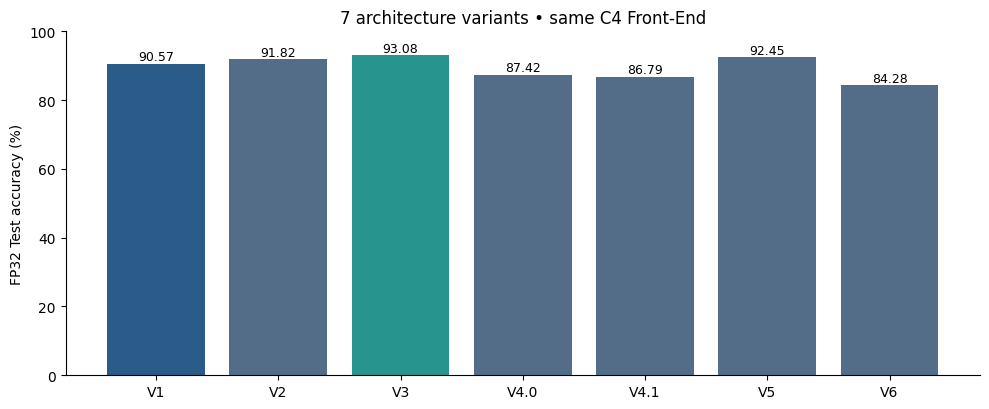

In [33]:
fig,ax=plt.subplots(figsize=(10,4.2))
xs=np.arange(len(MODELS))
vals=[SNAPSHOT_TRAIN[m]['acc'] for m in MODELS]
ax.bar(xs,vals,color=['#536c87' if m not in ['V1','V3'] else ('#2b5c89' if m=='V1' else '#27958d') for m in MODELS])
ax.set_xticks(xs,MODELS);ax.set_ylim(0,100);ax.set_ylabel('FP32 Test accuracy (%)')
for i,v in enumerate(vals):ax.text(i,v+1,f'{v:.2f}',ha='center',fontsize=9)
ax.set_title('7 architecture variants • same C4 Front-End');ax.spines[['top','right']].set_visible(False)
plt.tight_layout();plt.show()

**Diễn giải:** V3 đứng đầu FP32 Test (93,08%, FN=3) và V5 đứng thứ hai (92,45%). V1 FP32 đạt 90,57% (FN=8). Vì mục tiêu là chạy trên ESP32-S3, **thứ hạng FP32 không phải quyết định cuối**: phải xét thay đổi sau lượng tử hóa và `Invoke` trên board.

## 3. Lượng tử hóa — FP32, PTQ INT8, QAT INT8, PTQ INT16×8

Dữ liệu trích đúng từ 7 `Quantization_Report`, gồm kích thước file TFLite, Accuracy, Macro F1, Asthma Recall, FN/FP. `PTQ_INT16x8` giữ làm **tham khảo nghiên cứu**, chưa xác minh runtime TFLM ESP32-S3.

In [34]:
records=[]
for m in MODELS:
    for method in ['Keras_FP32','TFLite_FP32','PTQ_INT8','QAT_INT8','PTQ_INT16x8']:
        s=SNAPSHOT_QUANT[m][method]
        records.append({'Model':m,'Method':method,'Test Acc (%)':s['acc'],'Asthma Recall (%)':s['recall'],
                        'Macro F1 (%)':s['macro'],'FN':s['fn'],'FP':s['fp'], 'Size (B)':s['size_b']})
long_df=pd.DataFrame(records)
acc_wide=long_df.pivot(index='Model',columns='Method',values='Test Acc (%)').reindex(MODELS)
acc_wide=acc_wide[['Keras_FP32','PTQ_INT8','QAT_INT8','PTQ_INT16x8']]
acc_wide.insert(0, 'Parameters', [SNAPSHOT_TRAIN[model]['parameter_count'] for model in MODELS])
display(acc_wide.round(2))
print('Phiên bản INT8 thắng trong mỗi model:')
for m in MODELS:
    sub=long_df[(long_df.Model==m)&(long_df.Method.isin(['PTQ_INT8','QAT_INT8']))].sort_values('Test Acc (%)',ascending=False)
    win=sub.iloc[0]
    print(f"{m}: {win['Method']} — {win['Test Acc (%)']:.2f}% | FN={int(win['FN'])} | FP={int(win['FP'])}")

Method,Parameters,Keras_FP32,PTQ_INT8,QAT_INT8,PTQ_INT16x8
Model,,,,,
V1,331386,90.57,92.45,93.08,90.57
V2,7802,91.82,88.68,92.45,91.82
V3,23617,93.08,93.71,87.42,93.71
V4.0,1371361,87.42,88.05,88.68,87.42
V4.1,480321,86.79,86.79,92.45,88.05
V5,351553,92.45,90.57,89.31,92.45
V6,8401,84.28,72.96,84.91,84.28


Phiên bản INT8 thắng trong mỗi model:
V1: QAT_INT8 — 93.08% | FN=4 | FP=7
V2: QAT_INT8 — 92.45% | FN=6 | FP=6
V3: PTQ_INT8 — 93.71% | FN=3 | FP=7
V4.0: QAT_INT8 — 88.68% | FN=4 | FP=14
V4.1: QAT_INT8 — 92.45% | FN=2 | FP=10
V5: PTQ_INT8 — 90.57% | FN=5 | FP=10
V6: QAT_INT8 — 84.91% | FN=3 | FP=21


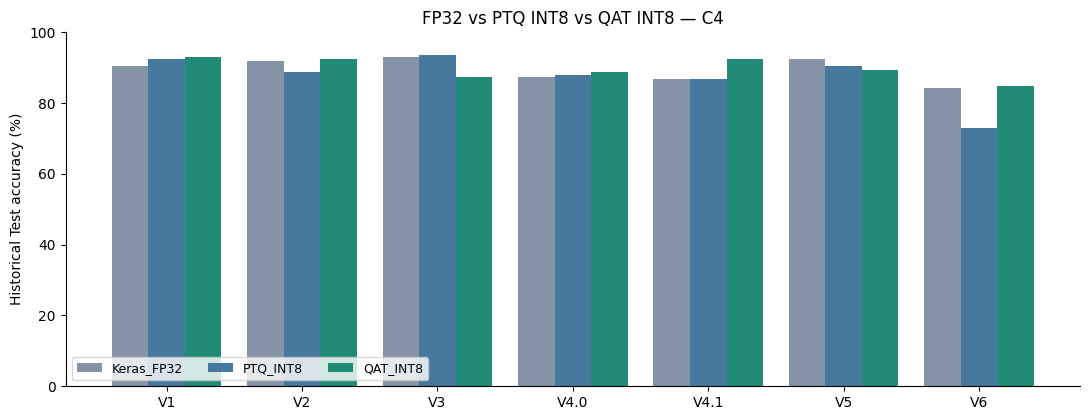

In [35]:
fig,ax=plt.subplots(figsize=(11,4.3))
x=np.arange(len(MODELS));width=.27
for i,(method,color) in enumerate([('Keras_FP32','#8593a6'),('PTQ_INT8','#47789e'),('QAT_INT8','#228b78')]):
    ax.bar(x+(i-1)*width,[SNAPSHOT_QUANT[m][method]['acc'] for m in MODELS],width,label=method,color=color)
ax.set_xticks(x,MODELS);ax.set_ylabel('Historical Test accuracy (%)');ax.set_ylim(0,100)
ax.set_title('FP32 vs PTQ INT8 vs QAT INT8 — C4');ax.legend(ncol=3,loc='lower left',fontsize=9)
ax.spines[['top','right']].set_visible(False);plt.tight_layout();plt.show()

**Kết quả đáng chú ý:** V3 có **PTQ INT8 93,71%**, file **47.448 B** và FN/FP **3/7**; QAT V3 chỉ 87,42%. V2/QAT nhỏ nhất trong nhóm ứng viên mạnh (~22.944 B), nhưng FN=6. V1 QAT ở **bộ báo cáo mới** là **93,08%**, **khác** checkpoint V1 QAT đã profiling (95,60%). Không trộn hai bản vào cùng một cột.

,Model,PTQ INT8 (KB),QAT INT8 (KB)
0,V1,347.37,347.96
1,V2,23.14,22.94
2,V3,47.45,51.73
3,V4.0,"1,534.93","1,540.54"
4,V4.1,568.36,575.87
5,V5,364.17,364.78
6,V6,27.17,28.04


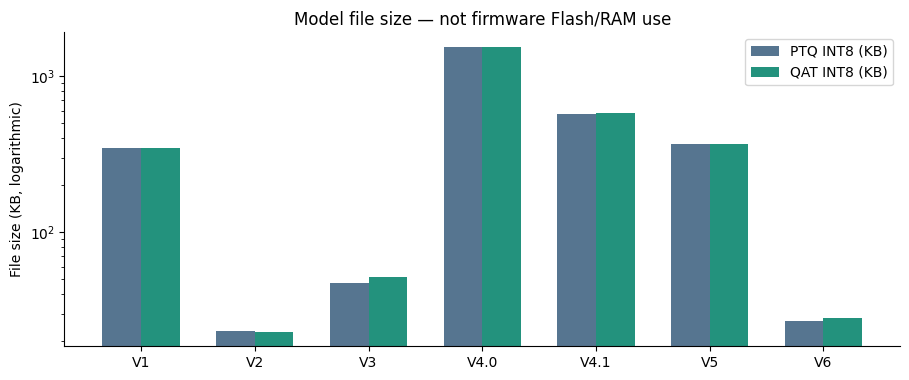

In [36]:
size_df=pd.DataFrame([{'Model':m,'PTQ INT8 (KB)':SNAPSHOT_QUANT[m]['PTQ_INT8']['size_b']/1000,
                          'QAT INT8 (KB)':SNAPSHOT_QUANT[m]['QAT_INT8']['size_b']/1000} for m in MODELS])
display(size_df.round({'PTQ INT8 (KB)':2,'QAT INT8 (KB)':2}))
fig,ax=plt.subplots(figsize=(9.2,3.9));x=np.arange(len(MODELS));w=.34
for d,c,delta in [('PTQ INT8 (KB)','#567590',-w/2),('QAT INT8 (KB)','#23927d',w/2)]: ax.bar(x+delta,size_df[d],w,color=c,label=d)
ax.set_xticks(x,MODELS);ax.set_yscale('log');ax.set_ylabel('File size (KB, logarithmic)');ax.set_title('Model file size — not firmware Flash/RAM use')
ax.legend();ax.spines[['top','right']].set_visible(False);plt.tight_layout();plt.show()

### **KẾT LUẬN TẠM THỜI**

Xét theo các tiêu chí, ta có thể thấy:
- Chọn theo các phiên bản của FP32, ta có thể thấy 
```text
V3 > V5 > V2 > V1 > V4.0 > V4.1 > V6
```
- Tuy nhiên khi sang lượng tử, kết quả có sự thay đổi khi sắp xếp phiên bản INT8 thắng
```text
PTQ V3 > QAT V1 > QAT V2 == QAT V4.1 > PTQ V5 > V4.0
```
- Một điều có thể quan tâm đến tổng số Parameter
```text
V4.0 > V4.1 > V5 > V1 > V3 > V2
```

Điều đó có thể rút ra được các kết luận tạm thời như
- `V3` là cấu trúc có khối lượng parameter tốt và độ accuracy khi lượng tử cao nhất, đáng để khảo sát tiếp
- `V5` và `V1` tuy cấu trúc gần giống nhau, bản lượng tử `V1` chiếm ưu thế hơn so với V5
- Hơn nữa, `V1` dùng SeparableConv2D tối ưu tính toán hơn so với `V5`, nên `V1` sẽ ưu tiên đi đo đạc thử nghiệm triển khai với `V3`

## 4. Kiểm thử ESP32-S3 — so sánh V1 QAT và V3 PTQ

**Nguồn log trong project:** `Phase4_Deployment_Artifacts/Log_Deploy/V1_C4_QAT.log` và `V3_C4_PTQ.log`. Snapshot V1 tương ứng với log gốc `C4_QAT(1).log`; snapshot V3 tương ứng với `V3_C4_PTQ.log`.

**Điều kiện:** CPU 240 MHz; AllOpsResolver; TensorArena **cấp phát 1.048.576 B PSRAM**; 36 lượt suy luận thành công cho mỗi model. Ở đây `Arena used` chỉ mô tả lượng arena mà TFLM báo sử dụng, **không phải tổng mức RAM toàn chương trình**.

In [37]:
board_df=pd.DataFrame([{'Candidate':key,'Model file (B)':v['model_size_b'],'Arena used (B)':v['arena_used_b'],
                             'Arena allocated (B)':v['arena_capacity_b'], 'Invoke avg (ms)':v['latency_ms'],
                             'Invoke pass':v['count'],'Static correct':v['static'],'Python=ESP exact':v['exact'],
                             'Label parity':v['label'],'Ops':v['compatibility']} for key,v in SNAPSHOT_BOARD.items()])
display(board_df.round({'Invoke avg (ms)':2}))
v1=SNAPSHOT_BOARD['V1/QAT (artifact đã profiling)'];v3=SNAPSHOT_BOARD['V3/PTQ']
print(f"V3 model size smaller: {v1['model_size_b']/v3['model_size_b']:.2f}x")
print(f"V3 Invoke slower: {v3['latency_ms']/v1['latency_ms']:.2f}x")
print(f"V3 arena used higher: {v3['arena_used_b']-v1['arena_used_b']:,} B")

,Candidate,Model file (B),Arena used (B),Arena allocated (B),Invoke avg (ms),Invoke pass,Static correct,Python=ESP exact,Label parity,Ops
0,V1/QAT (artifact đã profiling),"347,968.00","169,380.00","1,048,576.00","1,164.20",36/0,12/12,11/12,12/12,PASS
1,V3/PTQ,"47,448.00","173,188.00","1,048,576.00","11,452.18",36/0,12/12,12/12,12/12,PASS


V3 model size smaller: 7.33x
V3 Invoke slower: 9.84x
V3 arena used higher: 3,808.0 B


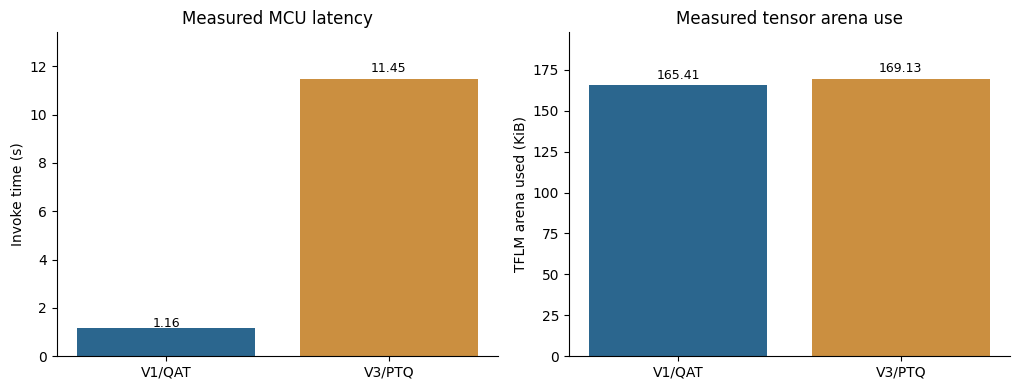

In [38]:
fig,axs=plt.subplots(1,2,figsize=(10.3,4.0))
keys=['V1/QAT','V3/PTQ'];colors=['#2b668e','#cb8f40']
axs[0].bar(keys,[v1['latency_ms']/1000,v3['latency_ms']/1000],color=colors)
axs[0].set_ylabel('Invoke time (s)');axs[0].set_title('Measured MCU latency')
axs[1].bar(keys,[v1['arena_used_b']/1024,v3['arena_used_b']/1024],color=colors)
axs[1].set_ylabel('TFLM arena used (KiB)');axs[1].set_title('Measured tensor arena use')
for a in axs:
    a.spines[['top','right']].set_visible(False)
    for bar in a.patches:a.text(bar.get_x()+bar.get_width()/2,bar.get_height()*1.025,f'{bar.get_height():.2f}',ha='center',fontsize=9)
    a.set_ylim(0,max(p.get_height() for p in a.patches)*1.17)
plt.tight_layout();plt.show()

### Phân tích tính đúng đắn và giới hạn

- **V3/PTQ**: 36/36 inference PASS; Python/ESP32 raw INT8 **12/12**; nhãn **12/12**; `Invoke` trung bình **11,452 s**.
- **V1/QAT đã profiling**: 36/36 PASS; raw INT8 exact **11/12**, nhãn **12/12**; `Invoke` trung bình **1,164 s**. Có **một mẫu raw output khác 61 LSB** giữa Python/ESP nhưng không đổi nhãn; **chưa đạt raw parity tuyệt đối**.
- Bộ kiểm thử chỉ gồm **12 tensor tĩnh**, không đo lại test 159 WAV trên MCU; `12/12` **không phải** Accuracy đại diện trên dữ liệu mới.
- Chưa tính thời gian thu âm 5 giây, DSP hoặc nhiễu microphone. Log không giải thích nguyên nhân sâu của mức trễ V3; không tự kết luận do một toán tử cụ thể.

**Hàm ý hệ thống:** Với chu kỳ cửa sổ thu 5 s, `Invoke` V3 (11,45 s) đã vượt thời lượng cửa sổ, trong khi V1 (~1,16 s) còn ngân sách cho DSP. Điều này hỗ trợ chọn V1 nếu hướng tới vận hành theo chu kỳ; **chưa chứng minh realtime toàn hệ thống**.

## 5. Mức chiếm dụng Flash/RAM **toàn chương trình** — ghi nhận người thực hiện

Ghi nhận từ lần build/deploy của nhóm: **Flash khoảng 30%**, **RAM khoảng 40–50%**. Các tỷ lệ này **không xuất hiện trong hai log static profiling**, nên đây là **ước lượng thực địa do người thực hiện cung cấp**, chưa phải số đo có nguồn từ build report trong notebook.

Không suy ra Flash toàn chương trình bằng `model.tflite bytes / flash chip bytes`; cũng không suy ra RAM hệ thống bằng `TensorArena used / tổng SRAM`. RAM cần phân biệt **internal SRAM**, **PSRAM** và memory sử dụng tạm trong DSP/microphone.

In [39]:
# Có thể thay bằng số đo thực tế từ build log (PlatformIO/Arduino IDE) khi sẵn có.
FLASH_PROGRAM_PCT_USER = 30.0   # Người thực hiện ghi nhận xấp xỉ
RAM_PROGRAM_PCT_USER_RANGE = (40.0, 50.0)   # Người thực hiện ghi nhận xấp xỉ
RESOURCE_REPORT_VERIFIED = False
resource_note=pd.DataFrame([
    {'Chỉ số':'Flash toàn chương trình','Ghi nhận':f'≈{FLASH_PROGRAM_PCT_USER:.0f}%','Nguồn':'Quan sát người thực hiện (chưa có build log)'},
    {'Chỉ số':'RAM toàn chương trình','Ghi nhận':f'≈{RAM_PROGRAM_PCT_USER_RANGE[0]:.0f}–{RAM_PROGRAM_PCT_USER_RANGE[1]:.0f}%','Nguồn':'Quan sát người thực hiện (chưa rõ tỷ lệ internal/PSRAM)'},
    {'Chỉ số':'TFLM arena used V1','Ghi nhận':f"{v1['arena_used_b']:,} B",'Nguồn':'Log ESP32-S3 (đã đo)'},
    {'Chỉ số':'TFLM arena used V3','Ghi nhận':f"{v3['arena_used_b']:,} B",'Nguồn':'Log ESP32-S3 (đã đo)'}])
display(resource_note)
print('Thông điệp:', 'Nếu tài nguyên đủ dư dả thì tốc độ Invoke và chất lượng phân loại trở thành ưu tiên mạnh hơn việc giảm file model bằng mọi giá.')

,Chỉ số,Ghi nhận,Nguồn
0,Flash toàn chương trình,≈30%,Quan sát người thực hiện (chưa có build log)
1,RAM toàn chương trình,≈40–50%,Quan sát người thực hiện (chưa rõ tỷ lệ intern...
2,TFLM arena used V1,"169,380.0 B",Log ESP32-S3 (đã đo)
3,TFLM arena used V3,"173,188.0 B",Log ESP32-S3 (đã đo)


Thông điệp: Nếu tài nguyên đủ dư dả thì tốc độ Invoke và chất lượng phân loại trở thành ưu tiên mạnh hơn việc giảm file model bằng mọi giá.


## 6. Kiểm toán hai artifact V1/QAT — không gộp nhầm báo cáo

| Artifact | Test accuracy | Model size | Tình trạng |
|---|---:|---:|---|
| `V1/C4/s44/QAT` trong bộ 72 model nghiên cứu (D), artifact đã static profiling | **95,597% (152/159)** | **347.968 B** | Đã đo MCU 36/36; chưa có SHA256 file `.tflite` ở đây |
| `V1/QAT` trong `Phase3_Quantization_Model` báo cáo mới | **93,082% (148/159)** | **347.960 B** | Chưa xác nhận cùng QAT recipe/artifact; không có log MCU tương ứng |

**Không khẳng định hai file là một model** dù cùng mô hình FP32 nguồn và Front-End C4. Chênh 4/159 mẫu đúng trên Test; muốn truy vết đầy đủ cần SHA256 của `.tflite`, script/recipe và bản ghi seed QAT. Việc khóa nguyên mẫu hiện tại **không đòi hỏi retrain**, nhưng file firmware phải trỏ đúng artifact **347.968 B** đã đo.

In [40]:
audit=pd.DataFrame([
 {'Artifact':'V1 QAT / D / đã profiling','Acc (%)':100*152/159,'Đúng/159':152,'FN':3,'FP':4,'Size (B)':v1['model_size_b'],'Board check':'PASS'},
 {'Artifact':'V1 QAT / Quantization_Report mới','Acc (%)':SNAPSHOT_QUANT['V1']['QAT_INT8']['acc'],
  'Đúng/159':SNAPSHOT_QUANT['V1']['QAT_INT8']['correct'],'FN':SNAPSHOT_QUANT['V1']['QAT_INT8']['fn'],
  'FP':SNAPSHOT_QUANT['V1']['QAT_INT8']['fp'],'Size (B)':SNAPSHOT_QUANT['V1']['QAT_INT8']['size_b'],'Board check':'Chưa xác minh'},
 {'Artifact':'V3 PTQ / Quantization_Report','Acc (%)':SNAPSHOT_QUANT['V3']['PTQ_INT8']['acc'],
  'Đúng/159':SNAPSHOT_QUANT['V3']['PTQ_INT8']['correct'],'FN':SNAPSHOT_QUANT['V3']['PTQ_INT8']['fn'],
  'FP':SNAPSHOT_QUANT['V3']['PTQ_INT8']['fp'],'Size (B)':v3['model_size_b'],'Board check':'PASS'}])
display(audit.round({'Acc (%)':3}))
assert audit['Đúng/159'].tolist()==[152,148,149]

,Artifact,Acc (%),Đúng/159,FN,FP,Size (B),Board check
0,V1 QAT / D / đã profiling,95.60,152,3,4,"347,968.00",PASS
1,V1 QAT / Quantization_Report mới,93.08,148,4,7,"347,960.00",Chưa xác minh
2,V3 PTQ / Quantization_Report,93.71,149,3,7,"47,448.00",PASS


## 7. Kết luận lựa chọn — theo mục tiêu MCU hạn chế tài nguyên

### Điều kiện lựa chọn

1. **Chất lượng phân loại theo lớp**, đặc biệt Asthma Recall/FN, không chỉ Accuracy tổng.
2. **Đủ Flash/RAM thực tế**; nếu hệ thống còn dư nhiều như ghi nhận (~30% Flash, ~40–50% RAM), giảm vài trăm KB model **không phải mục tiêu tối thượng**.
3. **Invoke nhanh** trên ESP32-S3 (quan trọng hơn đếm trọng số thuần túy).
4. **TFLM chạy ổn định và parity nhãn**, không lẫn với chẩn đoán y khoa.

### Kết luận trong phạm vi các checkpoint đã đo

**Ưu tiên giữ V1 / C4 / seed 44 / QAT INT8 (artifact đã profiling)** cho nguyên mẫu. V3/PTQ tuy nhẹ hơn nhiều và raw-parity tốt hơn, nhưng `Invoke` chậm ~9,84 lần, arena dùng nhỉnh hơn V1 và historical Test kém 3 mẫu so với bản V1/QAT đã profiling. Hai model đều tương thích TFLM trên board trong điều kiện thử.

**Không khẳng định V1 nhỏ nhất, ổn định nhất với dữ liệu mới hoặc tối ưu toàn cục**. Benchmark đầy đủ của các kiến trúc còn hạn chế do thiếu Val đồng nhất trong bộ Test_Report hiện tại, các seed khác nhau và historical Test đã được tham khảo nhiều lần. Khuyến nghị **khóa artifact đúng SHA và chuyển sang kiểm chứng DSP + microphone**, không cần tiếp tục săn seed/train model để kết luận vòng hiện tại.

## 8. Bảng số liệu rút gọn dùng trong báo cáo NCKH

Chạy cell dưới để sinh hai bảng cuối và có thể copy trực tiếp ra CSV cùng thư mục notebook nếu muốn.

In [41]:
summary=pd.DataFrame([{
 'Model':m,'FP32 Acc %':SNAPSHOT_TRAIN[m]['acc'],'PTQ Acc %':SNAPSHOT_QUANT[m]['PTQ_INT8']['acc'],
 'QAT Acc %':SNAPSHOT_QUANT[m]['QAT_INT8']['acc'],
 'PTQ size B':SNAPSHOT_QUANT[m]['PTQ_INT8']['size_b'],
 'QAT size B':SNAPSHOT_QUANT[m]['QAT_INT8']['size_b'],
 'PTQ FN':SNAPSHOT_QUANT[m]['PTQ_INT8']['fn'], 'QAT FN':SNAPSHOT_QUANT[m]['QAT_INT8']['fn']
} for m in MODELS])
display(summary.round({'FP32 Acc %':2, 'PTQ Acc %':2, 'QAT Acc %':2}))
print('Board comparison:');display(board_df)
# Đổi True nếu bạn thật sự muốn ghi file CSV vào thư mục hiện tại.
EXPORT_CSV = False
if EXPORT_CSV:
    summary.to_csv(ROOT/'Benchmark_C4_Models_Summary.csv',index=False,encoding='utf-8-sig')
    board_df.to_csv(ROOT/'Benchmark_C4_ESP32_Profiling.csv',index=False,encoding='utf-8-sig')
    print('Đã ghi 2 CSV tại:',ROOT.resolve())

,Model,FP32 Acc %,PTQ Acc %,QAT Acc %,PTQ size B,QAT size B,PTQ FN,QAT FN
0,V1,90.57,92.45,93.08,347368,347960,8,4
1,V2,91.82,88.68,92.45,23144,22944,6,6
2,V3,93.08,93.71,87.42,47448,51728,3,5
3,V4.0,87.42,88.05,88.68,1534928,1540544,6,4
4,V4.1,86.79,86.79,92.45,568360,575872,6,2
5,V5,92.45,90.57,89.31,364168,364776,5,5
6,V6,84.28,72.96,84.91,27168,28040,0,3


Board comparison:


,Candidate,Model file (B),Arena used (B),Arena allocated (B),Invoke avg (ms),Invoke pass,Static correct,Python=ESP exact,Label parity,Ops
0,V1/QAT (artifact đã profiling),"347,968.00","169,380.00","1,048,576.00","1,164.20",36/0,12/12,11/12,12/12,PASS
1,V3/PTQ,"47,448.00","173,188.00","1,048,576.00","11,452.18",36/0,12/12,12/12,12/12,PASS


---
### Nhật ký kiểm toán
- Snapshot báo cáo: 7 `Test_Report`, 7 `Quantization_Report`, 2 log `Log_Deploy`.
- C4 đầu vào: `40×129×1`, 5160 B/tensor INT8.
- Validation của **bảy kiến trúc mới** không được cung cấp trong bộ báo cáo hiện tại → **không dựng số liệu thay thế**.
- PTQ INT16x8 chỉ tham khảo; không tự nhận đã kiểm thử tương thích trên TFLM.
- `Arena capacity = 1 MiB PSRAM` là phần cấp phát thử nghiệm; `Arena used ≈ 165–169 KiB` là mức TFLM báo sử dụng; không suy ra % RAM chương trình.
- Flash/RAM 30%/40–50% là **ghi nhận của nhóm**, có thể cập nhật sau khi có log build thống nhất.
- Không thay thế yêu cầu đánh giá trên âm thanh thu mới từ microphone bằng Static Profiling.